# Lab 3c — Local Post-hoc Explainability on Structured Data: SHAP

This lab covers **SHAP (SHapley Additive exPlanations)** for explaining predictions of a black-box classifier on structured data.

### Learning objectives
By the end of the lab, you should be able to:
- build a SHAP explainer with the **modern unified API** (`shap.Explainer`);
- work consistently with a **`shap.Explanation`** object;
- interpret **local** explanations (bar, force, waterfall);
- interpret **global summaries** obtained by aggregating local SHAP values (bar, beeswarm, scatter/dependence);
- distinguish the **base value**, **feature contribution**, and **model output**.


## 🔍 What is SHAP?

SHAP assigns each feature a contribution to a prediction using ideas from **Shapley values** in cooperative game theory.
For one instance, the explanation satisfies the additive decomposition

$$
f(x) = \phi_0 + \sum_{j=1}^{d}\phi_j,
$$

where:
- $\phi_0$ is the **base value** (expected model output under the SHAP background distribution),
- $\phi_j$ is the SHAP contribution of feature \(j\),
- positive/negative values push the selected output respectively above/below the base value.

> **Important:** SHAP values are attributions under a particular masking/background assumption. They are not causal effects.


## ⚙️ Data preparation (~10 min)

We use the **Adult** dataset distributed through `shap.datasets.adult()` and train a Random Forest classifier.
The numeric representation is used by the model, while `display=True` provides readable categorical values for plots.


### ⚙️ Step 1 — Imports


In [2]:
!pip install -U shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 11.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
# If needed in a fresh environment:
# !pip install -U shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


### ⚙️ Step 2 — Load the Adult dataset


In [4]:
# Model-ready numeric representation
X, y = shap.datasets.adult()

# Human-readable representation of the same rows
X_display, y_display = shap.datasets.adult(display=True)

print("X shape:", X.shape)
X.head()


X shape: (32561, 12)


,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5


### ⚙️ Step 3 — Train/test split

> 🔑 **Key reminder:** the test set must remain unseen during model fitting. The SHAP background/masker will also be built from the **training set**, not the test set.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y #stratify=y car y= la classe à prédire (on veut conserver les proportions des classes à prédire)
    #Stratify signifie stratifier : conserver approximativement les mêmes proportions de chaque classe dans les deux ensembles.
)


### ⚙️ Step 4 — Train the black-box classifier


In [9]:
rf_clf = RandomForestClassifier(
    n_estimators=300, #nombre d'arbres de décisions (300-500 : bon compromis)
    random_state=42,
    n_jobs=-1 #utilise tout les coeurs disponibles
)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))


Test accuracy: 0.8536772608628896


### ⚙️ Step 5 — Select data to explain

To keep the lab fast, we explain only a subset of instances. The explanation is still computed **per instance**; later plots aggregate these local explanations.


In [ ]:
sample_data = X_test.iloc[:100].copy() #on prend une partie des instances du DataSet, on prend une copie pour ne pas modifier le dataset de départ
sample_X_display = X_display.loc[sample_data.index].copy() #on séléctionne les mêmes observations mais cette fois-ci dans X_display
#sample_X_display = X_display.iloc[:100].copy() #pareil si même ordre

print("Number of explained instances:", len(sample_data))

"""
Pourquoi X_display et pas X_train ?

X_train	Entraîner le modèle
X_test	Évaluer le modèle et sélectionner les observations à expliquer
X_display	Afficher les features dans un format lisible

X_display est donc destiné à rendre les explications SHAP plus compréhensibles pour un humain.
""" 

Number of explained instances: 100


## Exercise 1 — Build a SHAP explainer 🧩

We use the modern unified API:

```python
explainer = shap.Explainer(model, masker=masker)
shap_values = explainer(data)
```

The result is a **`shap.Explanation` object**. We will keep this object throughout the notebook instead of switching to the legacy `explainer.shap_values(...)` API.

**Your tasks:**
1. Build an `Independent` masker from the training data.
2. Create `shap.Explainer` using the fitted Random Forest model.
3. Inspect which specialized explainer SHAP selected automatically.


In [ ]:
#### START CODE HERE ####
# 1. Create an Independent masker using X_train (use max_samples=100)
masker = shap.maskers.Independent(X_train,max_samples=100) #masker dit quelle valeur neutre utiliser pour remplacer une feature.
#masker Independant : part du fait que les features sont indépendantes (remplace par valeur au hasard dans X_train)
#max_samples=100 : SHAP n'utilise que 100 valeurs au hasard de X_train pour limiter le temps de calcul pour une précision quasi similaire

# 2. Create the unified SHAP explainer using rf_clf and the masker
explainer = shap.Explainer(rf_clf,masker=masker) #moteur d'explication, choisit automatiquement le bon algorithme (ici TreeExplainer)
#### END CODE HERE ####

print("Selected explainer:", type(explainer).__name__)


Background dataset has 26048 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=26048 when initializing the masker.


Selected explainer: TreeExplainer


### 1.2 — Compute SHAP values as an `Explanation`

For a binary classifier, the explanation typically has shape

\[
(n_{\text{instances}}, n_{\text{features}}, n_{\text{classes}}).
\]

We select one output/class and continue working with that sliced **`Explanation` object**.


In [ ]:
#### START CODE HERE ####
# Compute one Explanation object for sample_data
shap_values = explainer(sample_data) #appel à notre explainer sur l'échantillon sample_data
print(shap_values[0])

""" 
cela va nous retourner une matrice composée de 3 choses : 

1. values: les contributions SHAP

12 lignes, 2 colonnes car 12 features et 2 classes possibles (<=50K et >50K)
Les contributions des deux classes sont exactement opposées (leur somme = 0)

2. bases_values: prédiction de référence

C'est le point de départ de l'explication :

0.767 = probabilité moyenne de prédire <=50K (sur le jeu de référence du masker)
0.233 = probabilité moyenne de prédire >50K
La formule SHAP : prédiction_finale = base_value + somme(valeurs SHAP de toutes les features)

3. data: les valeurs des features pour ce sample
""" 

# Explain the positive class (>50K)
class_index = 1
class_names = ["<=50K", ">50K"]

# Slice the Explanation object to retain only the selected class
shap_values_class = shap_values[:,:,class_index] #on garde tout les échantillons et samples, et juste la classe >50K

# Optional: attach readable feature values for plots
shap_values_class.display_data = sample_X_display.values
#### END CODE HERE ####

print("Explanation type:", type(shap_values))
print("All outputs shape:", shap_values.values.shape) #(100 échantillons,12 features et 2 classes possibles)
print("Selected class shape:", shap_values_class.values.shape) #on a slicé en 1 classe et plus 2, donc (100,12)


 98%|===================| 197/200 [00:31<00:00]        

.values =
array([[ 7.91784274e-02, -7.91784282e-02],
       [-1.00969527e-02,  1.00969524e-02],
       [-2.05052147e-01,  2.05052147e-01],
       [ 5.31378043e-02, -5.31378059e-02],
       [-2.04293211e-02,  2.04293224e-02],
       [ 1.46348650e-01, -1.46348654e-01],
       [-1.53613052e-03,  1.53613068e-03],
       [-2.75311325e-02,  2.75311329e-02],
       [ 1.03756479e-02, -1.03756474e-02],
       [ 8.98389659e-03, -8.98389636e-03],
       [ 1.25191462e-02, -1.25191461e-02],
       [ 5.28244198e-05, -5.28243039e-05]])

.base_values =
array([0.76738262, 0.23261738])

.data =
array([31.,  5., 16.,  4., 10.,  3.,  4.,  1.,  0.,  0., 40., 39.])
Explanation type: <class 'shap._explanation.Explanation'>
All outputs shape: (100, 12, 2)
Selected class shape: (100, 12)


### 1.3 — Check the additive decomposition

For an explained instance, SHAP should reconstruct the selected model output:

$
\text{base value} + \sum_j \text{SHAP}_j \approx f(x).
$

For this Random Forest explainer, the selected output corresponds to the class probability.


In [19]:
id_instance = 0

#### START CODE HERE ####
base_value = shap_values_class.base_values[id_instance]
contribution_sum = shap_values_class.values[id_instance].sum() #somme des 12 contributions SHAP vers >50K
reconstructed = base_value + contribution_sum
model_probability = rf_clf.predict_proba(sample_data[id_instance:id_instance+1])[0, 1]
#### END CODE HERE ####

print("Base value:          ", base_value)
print("Sum of SHAP values:  ", contribution_sum)
print("Reconstructed output:", reconstructed)
print("Model probability:   ", model_probability)


Base value:           0.23261738018268363
Sum of SHAP values:   -0.04595071702182397
Reconstructed output: 0.18666666316085967
Model probability:    0.18666666666666668


## Exercise 2 — Local explanations 🔎

A local explanation describes **one prediction**. We will inspect the same instance with three complementary plots.

**Your tasks:**
1. Create a local SHAP bar plot.
2. Create a force plot.
3. Create a waterfall plot.
4. Compare what information each visualization emphasizes.


### 2.1 — Local bar plot


Predicted probabilities: [0.87333333 0.12666667]


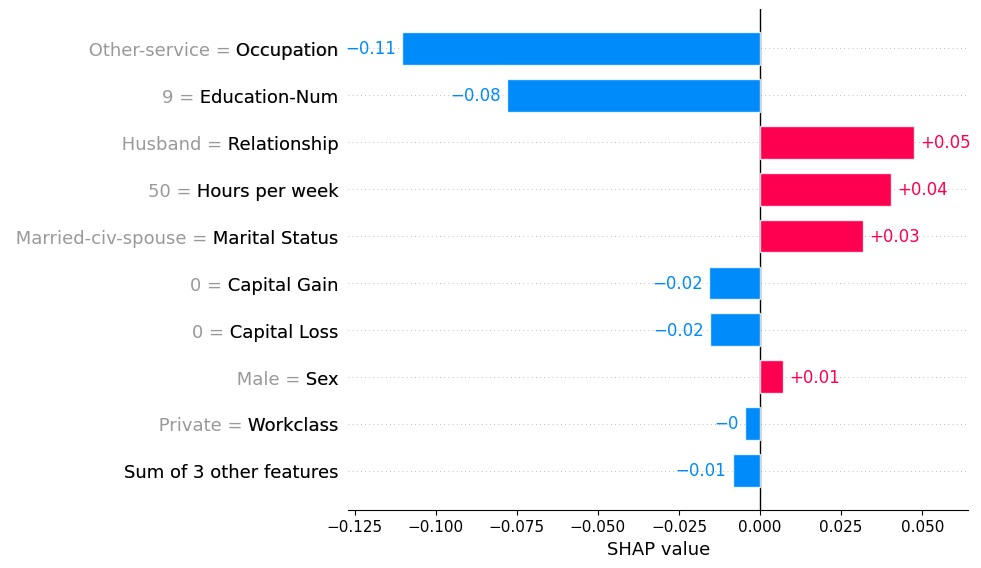

In [ ]:
id_instance = 50

print("Predicted probabilities:", rf_clf.predict_proba(sample_data.iloc[[id_instance]])[0])

#### START CODE HERE ####
shap.plots.bar(shap_values_class[id_instance], max_display=10) #rouge : pousse vers >50K et bleu : pousse vers <=50K
#### END CODE HERE ####

""" 
Le graphique permet d'identifier rapidement les variables qui influencent le plus une prédiction individuelle, ainsi que leur direction d'influence.
Dans notre exemple, Occupation et Education-Num sont les deux variables qui diminuent le plus la probabilité prédite.
""" 


### 2.2 — Force plot

The force plot starts from the **base value** and shows which features push the selected output upward or downward until it reaches the instance prediction.


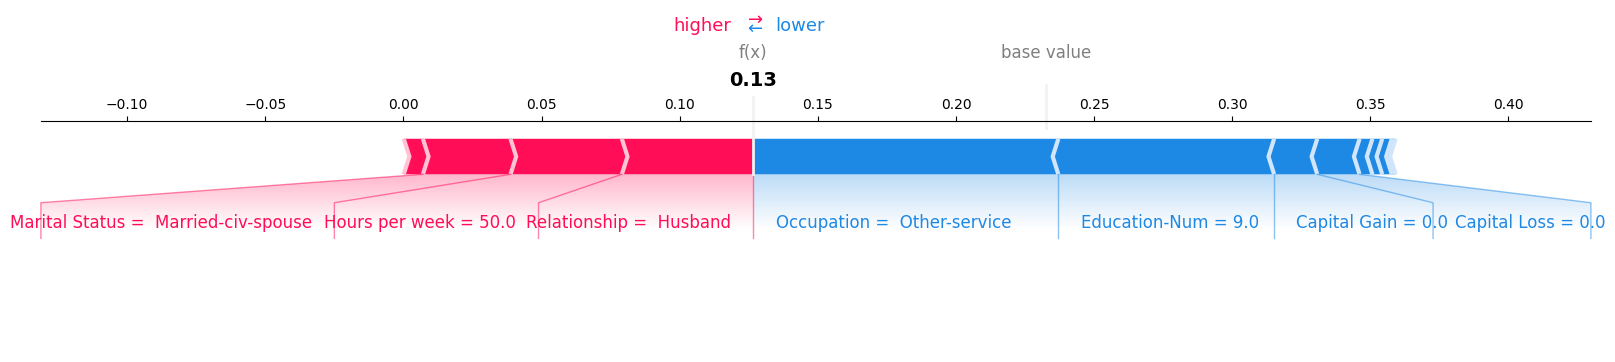

In [ ]:
#### START CODE HERE ####
# Create a force plot for shap_values_class[id_instance]
shap.plots.force(
    shap_values_class[id_instance],
    matplotlib=True
)
#### END CODE HERE ####

""" 
Le Force plot illustre le déplacement de la prédiction depuis la valeur de référence jusqu'à la prédiction finale.
Il est particulièrement intéressant pour comprendre rapidement quelles features poussent une prédiction dans un sens ou dans l'autre.
""" 


### 2.3 — Waterfall plot

The waterfall plot shows the same additive decomposition explicitly: starting from the expected output, feature contributions accumulate until the final model output is reached.


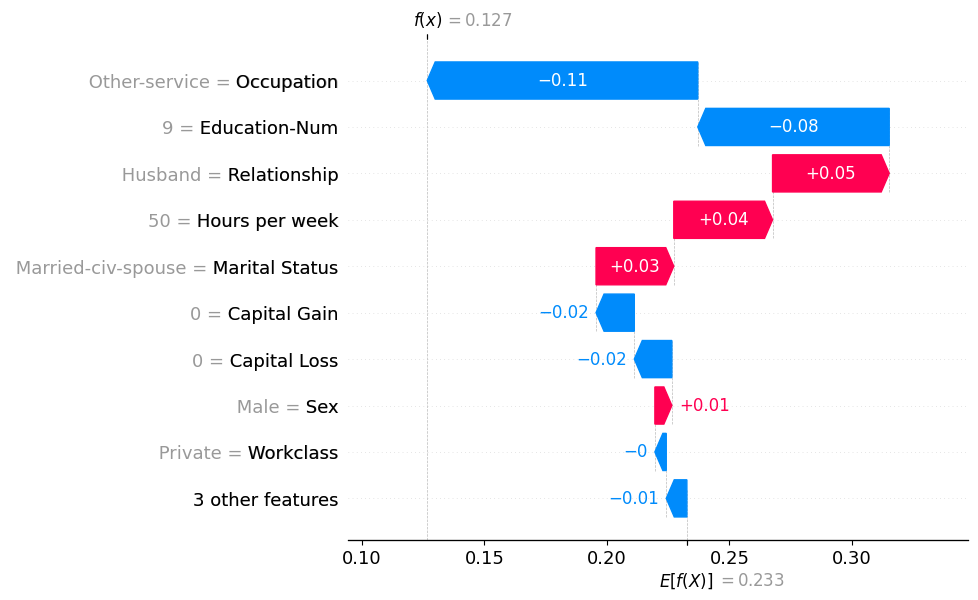

In [ ]:
#### START CODE HERE ####
# Create a waterfall plot for the same instance
shap.plots.waterfall(
    shap_values_class[id_instance],
    max_display=10
)
#### END CODE HERE ####

""" 
Le Waterfall plot est probablement le plus pédagogique des trois pour comprendre la décomposition mathématique d'une prédiction.
Il permet de suivre étape par étape la manière dont chaque feature modifie la valeur de référence.
""" 

## Exercise 3 — From local explanations to global summaries 🌍

SHAP values are computed locally, but we can aggregate them over many instances to summarize model behaviour.

> **Important:** these plots summarize the explained sample. They are not a causal description of the data-generating process.


### 3.1 — Global feature-importance bar plot

`shap.plots.bar()` applied to multiple rows ranks features using the mean absolute SHAP magnitude across the explained instances.


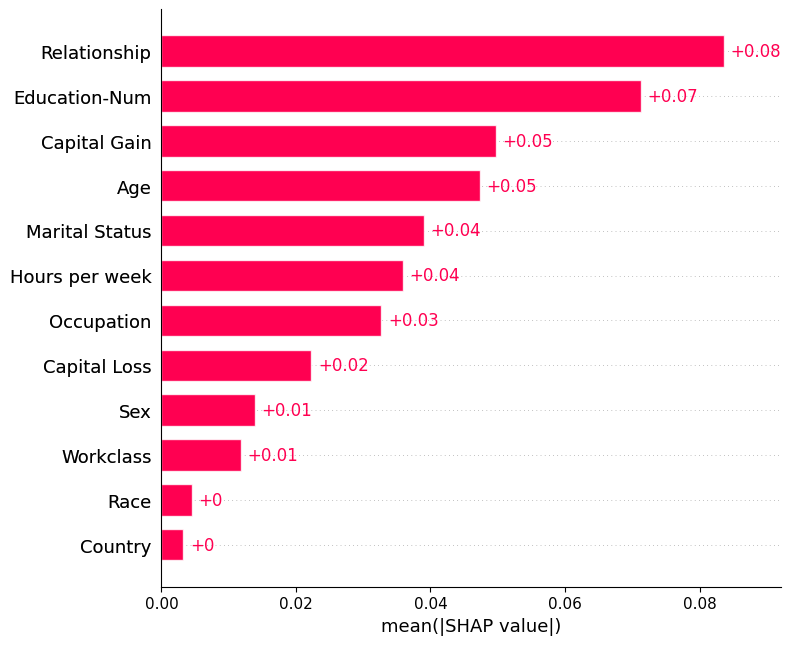

In [ ]:
#### START CODE HERE ####
# Plot global mean absolute SHAP importance
shap.plots.bar(shap_values_class, max_display=12)
#### END CODE HERE ####

""" 
Le Global bar plot permet de répondre à la question :
« Quelles sont les variables les plus importantes pour les prédictions de mon modèle, en moyenne ? »
Il ne donne cependant aucune information sur le sens de leur influence.
""" 

### 3.2 — Beeswarm plot

The beeswarm retains the **distribution and direction** of local contributions rather than collapsing each feature to one mean absolute value.


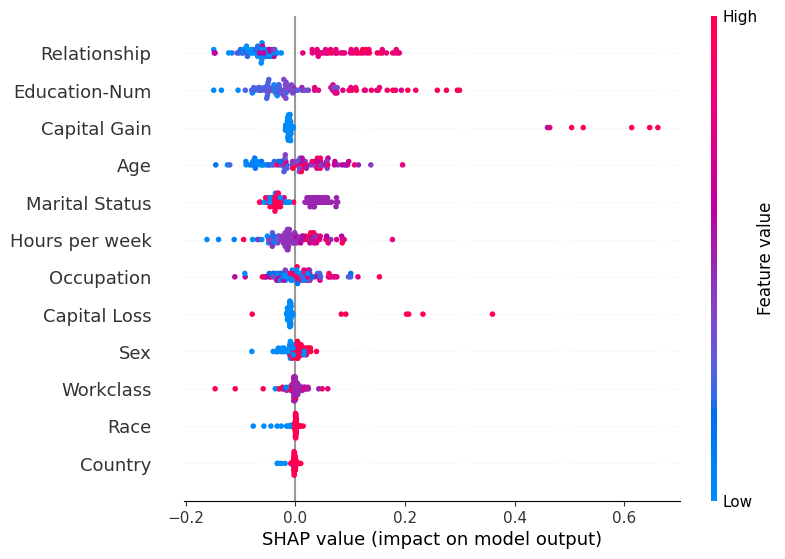

In [ ]:
#### START CODE HERE ####
# Plot the SHAP beeswarm for the selected class
shap.plots.beeswarm(shap_values_class, max_display=12)
#### END CODE HERE ####

""" 
Le Beeswarm plot est plus riche que le Global bar plot.
Il permet de répondre à la question :
« Quelles variables influencent les prédictions, dans quel sens et comment cette influence varie-t-elle selon les individus ? »
C'est un excellent graphique pour comprendre le comportement global d'un modèle.
""" 

### 3.3 — SHAP scatter / dependence plots

For a selected feature, the x-axis is the feature value and the y-axis is its SHAP contribution. Coloring by the full explanation can reveal potential interactions with other features.


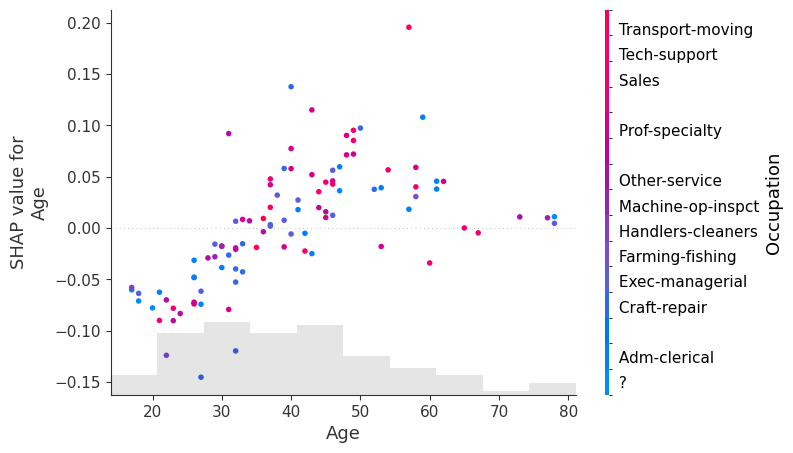

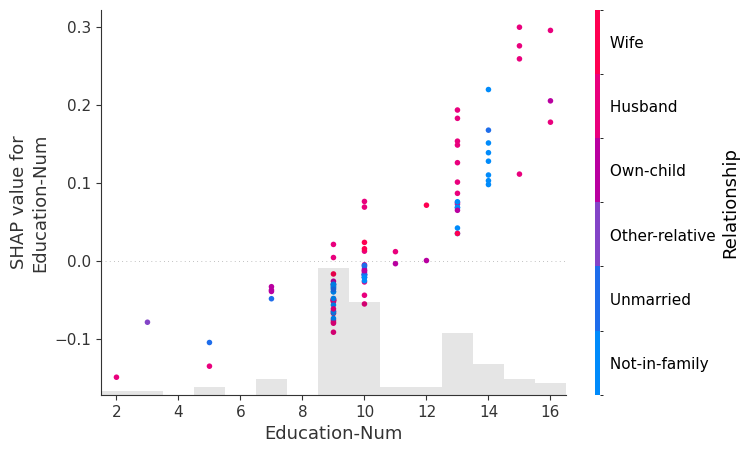

In [ ]:
selected_features = ["Age", "Education-Num"]

for feature_name in selected_features:
    shap.plots.scatter(
        shap_values_class[:, feature_name],
        color=shap_values_class
    )

""" 
Les dependence plots permettent d'étudier individuellement les relations entre les valeurs d'une feature et son influence sur les prédictions.

Ils sont particulièrement intéressants pour détecter :
- Des relations non linéaires.
- Des changements de comportement du modèle.
- Des interactions potentielles entre plusieurs features.
"""

### 3.4 — Force plot for multiple instances

The interactive multi-instance force plot lets you inspect how local attributions vary across a small set of observations.


In [29]:
shap.initjs()

In [30]:
#### START CODE HERE ####
# Visualize the first 10 explanations together
shap.plots.force(shap_values_class[:10])
#### END CODE HERE ####

### 🔍 Reflection Questions

1. **Base value vs prediction:** What does the SHAP base value represent? How do the individual feature contributions recover the model output for one instance?

2. **Local vs global:** Why is a large SHAP value for one individual not evidence that the same feature is globally important for every instance?


3. **Feature dependence:** What problem arises when correlated features are treated as independently maskable? How should this affect your interpretation of the attribution?

4. **Explainer choice:** Why is a tree-specific SHAP algorithm preferable to a fully model-agnostic method for a Random Forest when both are applicable?


### ✅ Suggested answers to the reflection questions

1. **Base value vs prediction.** The base value is the expected selected model output under the explainer's background distribution. For one instance, adding all SHAP contributions to that base value reconstructs the selected model output (up to numerical precision).

2. **Local vs global.** A SHAP value is conditional on the instance and on the coalition/masking context. A feature can strongly influence one prediction but have little effect elsewhere. Global SHAP plots aggregate many local explanations; they should not be inferred from a single case.


3. **Feature dependence.** Independent masking can create unrealistic feature combinations when predictors are correlated. Credit may then be distributed in a way that depends on the masking assumption. SHAP values should therefore be interpreted as model attributions under the chosen feature-dependence semantics, not as causal effects.

4. **Explainer choice.** Tree-aware SHAP exploits the structure of the Random Forest and computes attributions much more efficiently than generic perturbation-based methods. A model-agnostic method is useful when model internals are unavailable, but it generally requires many more model evaluations.

## ⭐ Optional — Compare with a model-specific SHAP explainer

* Redo your analysis with KernelExplainer or another Explainer
* Use a callable prediction function instead of the Random Forest object and inspect which explainer `shap.Explainer` selects. Compare:
  * computation time (hint: use colab magic command %%timeit)
  * output shape;
  * qualitative agreement of the most important features;
  * why algorithm-specific explainers can be substantially faster.
